<a href="https://colab.research.google.com/github/u5696834/u5696834-DataScience-GenAI-Submissions/blob/main/2_05_Seminar_03_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA) with Titanic Data Set
Implementing the directed learning into practice - seminar tasks with titanic data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic.csv


We can now import the data into pandas as before:

In [2]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


We can find the number of rows and columns with ".shape":

In [3]:
titanic.shape

(891, 12)

1000 rows and 7 columns. We can get informtaion about the data using the _info_ function:

In [4]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


We can see from this our data items are of the type 'object' (meaning string) or int64 (64-bit integers). We can also see that most have "891 non-null" records and there are "891 entries", however "Age" has 891-714 missing, "Cabin: has 891-204 missing, and "Embarked" has 891-889 missing. This represenation of "null" will be shown in the following code that examines it directly.

In [5]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


As seen "Age", "Cabin", and "Embarked" have null values, while other are all non-null

In [6]:
# Percent of data which is not available
titanic.isnull().sum()/len(titanic) * 100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


We can find the number of unique and duplicated rows:

In [7]:
titanic.duplicated().value_counts()

,count
False,891


No duplicates (i.e. there are 891 records for which its False that the record is a duplicate). Pandas will also give us summary statistics about this data:

In [8]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


We can see that only three of the columns have been "described" ... the three that were numeric (int64). For each, we get a range of useful measures including the mean average, the standard deviation, minimum and maximum values, and the 25th, 50th (median) and 75th percentyles.

### Visualising the Data

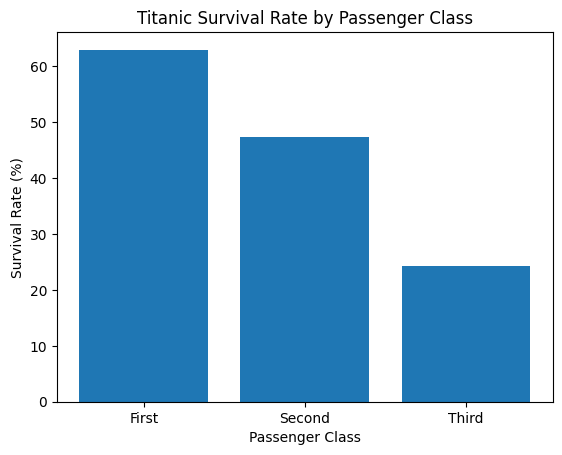

In [9]:
survival_by_class = titanic.groupby('Pclass')['Survived'].mean() * 100

plt.bar(survival_by_class.index, survival_by_class.values)
plt.xlabel('Passenger Class')
plt.xticks([1, 2, 3], ['First', 'Second', 'Third'])
plt.ylabel('Survival Rate (%)')
plt.title('Titanic Survival Rate by Passenger Class')
plt.show()

As seen, the higher the class you're in the higher the likelihood of survival. This suggests safety procedures and evacuation prioritized passengers based on class directly with First Class having over 60% survival being the highest followed by Second Class with little over 45%, and last is Third Class at slightly below 30% survival level.

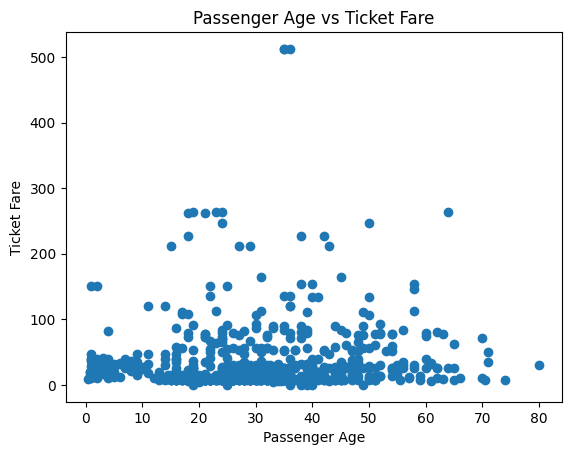

In [10]:
plt.scatter(titanic['Age'], titanic['Fare'])
plt.xlabel('Passenger Age')
plt.ylabel('Ticket Fare')
plt.title('Passenger Age vs Ticket Fare')
plt.show()

There appears to be little correlation between passenger age and ticket fare, with most passengers paying relatively low fares regardless of age. However, a few outliers stand out, particularly passengers paying fares exceeding £500.

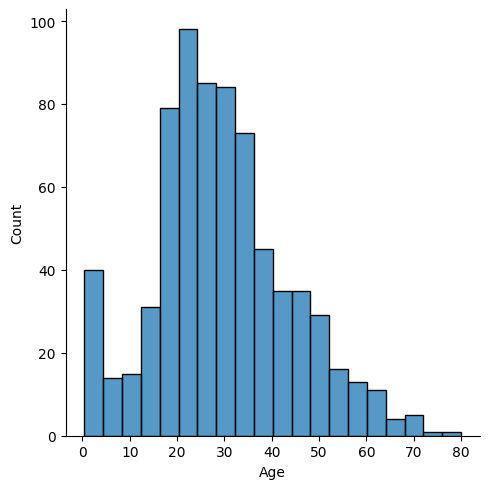

In [11]:
ax = sns.displot(titanic['Age'])

Passenger ages are concentrated between 20 and 35, with the highest frequency among those in their early twenties. The distribution is slightly right-skewed, with fewer older passengers, particularly those above 60.

We can use the _pairplot( )_ method to visualise pairs of variables:

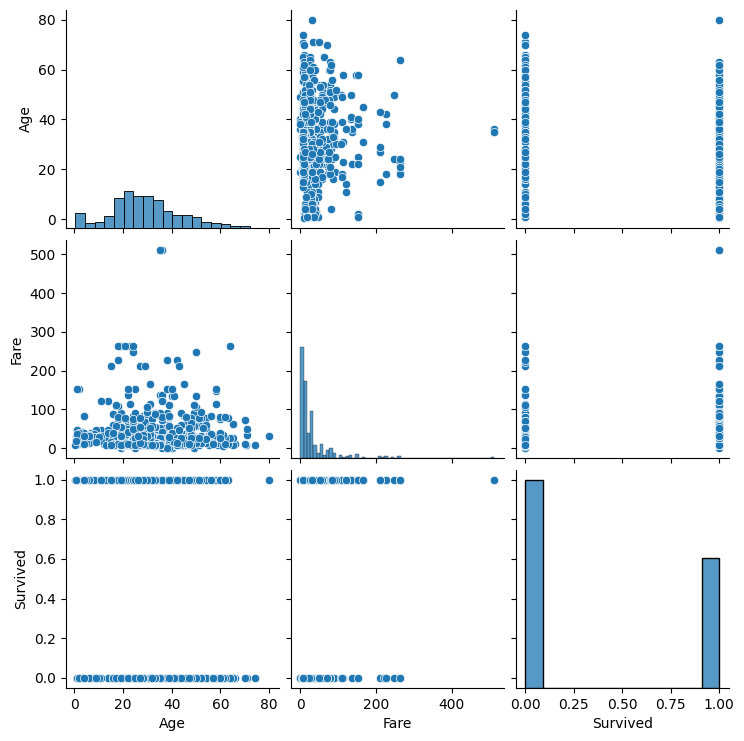

In [12]:
sns.pairplot(data = titanic[['Age', 'Fare', 'Survived']])

The pair plot shows that most passengers were young adults who paid relatively low fares. Ticket fares are strongly right-skewed, with a few significant outliers. There is no clear relationship between age and survival, although passengers paying higher fares appear more likely to have survived.



# Additional Investigation: Survival Rates by Sex



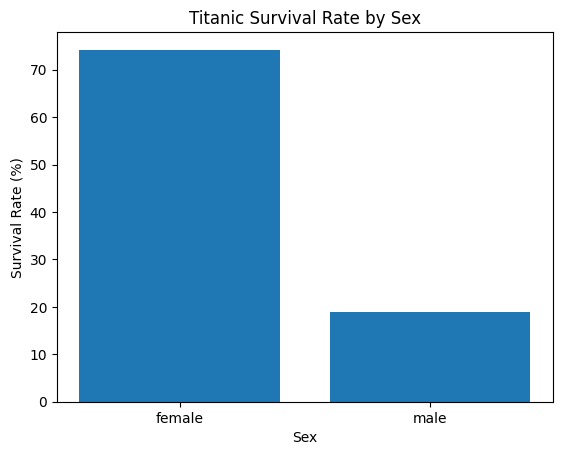

In [13]:
survival_by_sex = titanic.groupby('Sex')['Survived'].mean() * 100

plt.bar(survival_by_sex.index, survival_by_sex.values)
plt.xlabel('Sex')
plt.ylabel('Survival Rate (%)')
plt.title('Titanic Survival Rate by Sex')
plt.show()

Female passengers had a significantly higher survival rate roughly around 75% compared to male passengers around 20%. This suggests a strong association between sex and survival, potentially reflecting the prioritisation of women and children during evacuation.